<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BPractice%20DIAGNOSTIC%20Lesson%204%5D_DSA211_Simulated_Q1_Diagnostics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## How to use this question

This question is built entirely from **Lab 4 (Regression Diagnostics)**, on the same `Credit` data. Every step has already been done in the lab on a slightly different model. Nothing here is new.

- Work like the exam: about **18 minutes**, open book, no AI.
- For each part, find the matching lab cell, adapt the code to this model, run it, then write your answer in the markdown cell under the part label.
- Keep to the sentence limits. A printed number with no sentence earns at most half the marks.
- If you are stuck, the **📍 Where to look** note under each part tells you exactly which lab cell to open. Try first, then look.

The model for this question differs from Lab 4 in one place: `Cards` replaces `Age`.

***

## Setup

Run as given. It loads the data only: importing the libraries you need for each part is your job, as in the exam.

In [43]:
#Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as scipy_stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from statsmodels.graphics.regressionplots import plot_partregress_grid

In [44]:
import pandas as pd

url = "https://www.statlearning.com/s/Credit.csv"
credit = pd.read_csv(url)
credit.index = range(1, len(credit) + 1)
if "Unnamed: 0" in credit.columns:
    credit = credit.drop(columns=["Unnamed: 0"])

print("Shape:", credit.shape)
print("Customers with Balance = 0:", (credit["Balance"] == 0).sum())

Shape: (400, 11)
Customers with Balance = 0: 90


**Model for this question**

`Balance ~ Income + Limit + Rating + Cards + C(Student)`

***

**1(a)** Fit the model with statsmodels and draw the four standard diagnostic plots. Which assumption of the linear model is most clearly violated? Describe the evidence, and say what in the data causes it. **[2]** *(at most 3 sentences)*

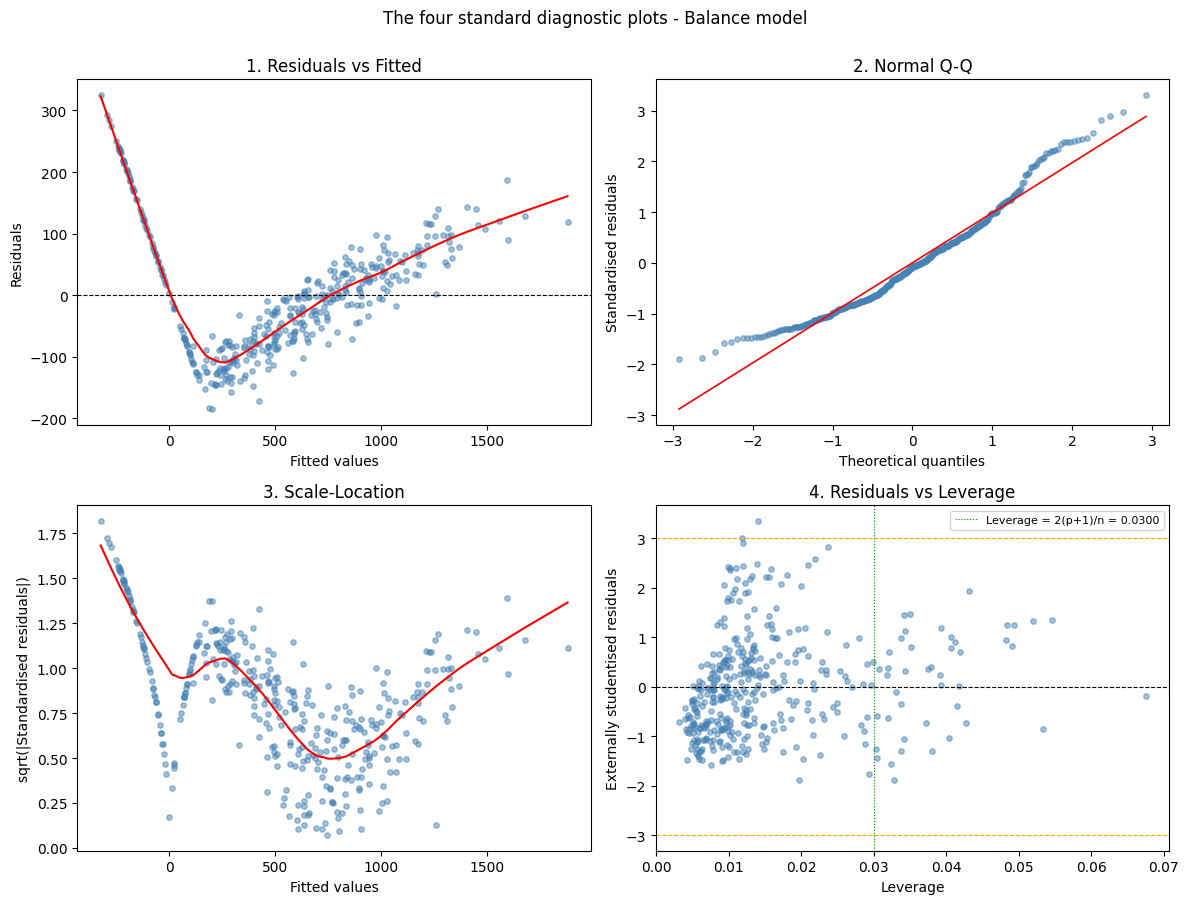

Largest |externally studentised residual|: 3.348
Observations above the leverage threshold: 44


In [45]:
### YOUR CODE HERE
model = smf.ols('Balance ~ Income + Limit + Rating + Cards + C(Student)', data=credit).fit()

#4 plots
fitted    = model.fittedvalues
residuals = model.resid
influence = OLSInfluence(model)
leverage        = pd.Series(influence.hat_matrix_diag,
                            index=credit.index) # wrapped
std_resid       = influence.resid_studentized_internal   # internally studentised
studentised_ext = influence.resid_studentized_external   # externally studentised
cooks_d         = influence.cooks_distance[0]

n = model.nobs
p = model.df_model                 # number of predictors, excluding the intercept
lev_threshold = 2 * (p + 1) / n

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1 - Residuals vs Fitted: linearity
ax = axes[0, 0] # position
ax.scatter(fitted, residuals, alpha=0.5, s=15, color='steelblue')
ax.axhline(0, color='black', lw=0.8, ls='--')
lo = sm.nonparametric.lowess(residuals, fitted, frac=0.3) # lowess
ax.plot(lo[:, 0], lo[:, 1], color='red', lw=1.5)
ax.set(xlabel="Fitted values", ylabel="Residuals", title="1. Residuals vs Fitted")

# 2 - Normal Q-Q: normality of the errors
ax = axes[0, 1]
(osm, osr), (slope, intercept, r) = scipy_stats.probplot(std_resid, dist="norm")
ax.scatter(osm, osr, alpha=0.5, s=15, color='steelblue')
ax.plot(osm, slope * np.array(osm) + intercept, color='red', lw=1.2)
ax.set(xlabel="Theoretical quantiles", ylabel="Standardised residuals", title="2. Normal Q-Q")

# 3 - Scale-Location: constant variance
ax = axes[1, 0]
sqrt_abs_resid = np.sqrt(np.abs(std_resid))
ax.scatter(fitted, sqrt_abs_resid, alpha=0.5, s=15, color='steelblue')
lo2 = sm.nonparametric.lowess(sqrt_abs_resid, fitted, frac=0.3)
ax.plot(lo2[:, 0], lo2[:, 1], color='red', lw=1.5)
ax.set(xlabel="Fitted values", ylabel="sqrt(|Standardised residuals|)",
       title="3. Scale-Location")

# 4 - Residuals vs Leverage: influence
ax = axes[1, 1]
ax.scatter(leverage, studentised_ext, alpha=0.5, s=15, color='steelblue')
ax.axhline(0, color='black', lw=0.8, ls='--')
for y in (3, -3):
    ax.axhline(y, color='orange', lw=0.8, ls='--')
ax.axvline(lev_threshold, color='green', lw=0.8, ls=':',
           label=f"Leverage = 2(p+1)/n = {lev_threshold:.4f}")
ax.legend(fontsize=8)
ax.set(xlabel="Leverage", ylabel="Externally studentised residuals",
       title="4. Residuals vs Leverage")

plt.suptitle("The four standard diagnostic plots - Balance model", y=1.00)
plt.tight_layout()
plt.show()

print(f"Largest |externally studentised residual|: {studentised_ext.abs().max():.3f}")
print(f"Observations above the leverage threshold: {(leverage > lev_threshold).sum()}")


**1(a)**
Which assumption of the linear model is most clearly violated? Describe the evidence, and say what in the data causes it. [2] (at most 3 sentences)
*Your answer here:*

I believe that there are two assumptions that are very clearly violated which are linearnity and homoscedasticity according to the Gauss-Markob Theorem's BLUE; however, the most clearly violated assumption is homoscedasticity. I believe so because, in plot 3, the red LOWESS clearly shows that variance decreases first, then increases with the mean; hence, the the dataset is heteroscedastic unlike the desired homoscedasticity. I believe this is due to the dataset containing many observations with a balance of 0, specifically 90; Balance can't be negative while the predicted line can, so, there are large residuals at the boundary which distorts the variance.

> 📍 **Where to look**
>
> - **Imports:** Lab 4, **Setup** cell (the first code cell). It has every library this question needs.
> - **Code:** Lab 4, **Part 1** (the `smf.ols(...)` cell), then **Part 2**: the first code cell (starts `fitted = model.fittedvalues`) builds the quantities, the second draws the 2×2 grid. Change the formula; nothing else.
> - **Reasoning:** Lab 4, **Question 2.1** (the four-panel table and "which is the most serious problem"). Lab 4 **Part 0** prints how many customers have `Balance = 0`; check where they sit on panel 1.

***

**1(b)** Using the course thresholds, report: the leverage threshold and how many observations exceed it; the Cook's distance threshold $4/n$ and how many exceed it; and how many observations have an externally studentised residual above 3 in absolute value. **[2]** *(at most 2 sentences)*

n = 400,  p = 5,  mean leverage (p+1)/n = 0.0150

measure     threshold  flagged
leverage       0.0300       44
cooks_d        0.0100       30
dffits         0.2449       30


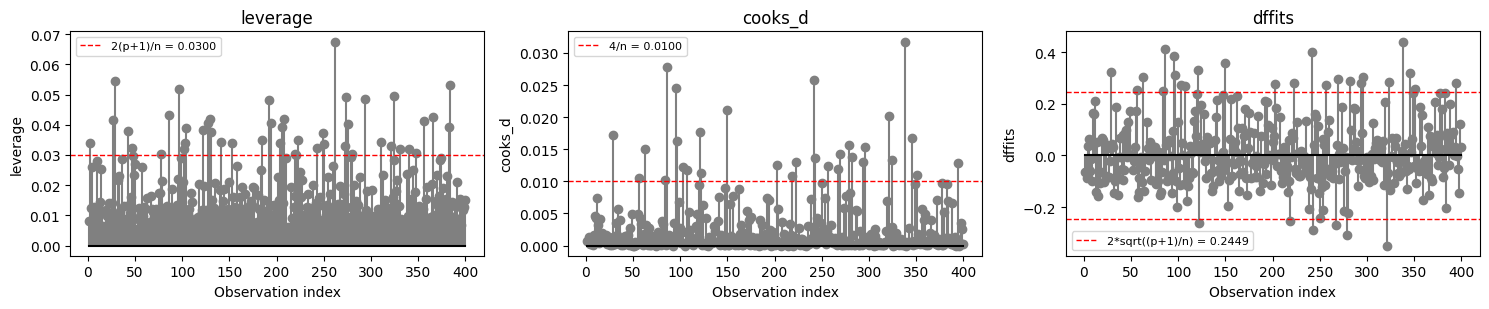

Largest |externally studentised residual|: 2
Observations above the leverage threshold: 44


In [46]:
### YOUR CODE HERE

diag = credit.copy()
diag["leverage"]  = leverage
diag["std_resid"] = studentised_ext
diag["cooks_d"]   = cooks_d
diag["dffits"]    = influence.dffits[0]      # .dffits returns (values, threshold)

# threholds
# leverage threshold computed above
cook_thresh_4n = 4 / n
dffits_thresh  = 2 * np.sqrt((p + 1) / n)

# Report red flags
print(f"n = {n:.0f},  p = {p:.0f},  mean leverage (p+1)/n = {(p + 1) / n:.4f}\n")
print(f"{'measure':10s} {'threshold':>10s} {'flagged':>8s}")
for col, thresh in [("leverage", lev_threshold), ("cooks_d", cook_thresh_4n),
                    ("dffits", dffits_thresh)]:
    print(f"{col:10s} {thresh:10.4f} {(diag[col].abs() > thresh).sum():8d}")
id_cols   = ["Income", "Limit", "Rating", "Age", "Student", "Balance"]
stat_cols = ["leverage", "std_resid", "cooks_d", "dffits"]

# The three influence index plots, side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, (col, thresh, formula) in zip(axes, [
        ("leverage", lev_threshold,  "2(p+1)/n"),
        ("cooks_d",  cook_thresh_4n, "4/n"),
        ("dffits",   dffits_thresh,  "2*sqrt((p+1)/n)")]):
    ax.stem(diag.index, diag[col], markerfmt='o', linefmt='grey', basefmt='black')
    ax.axhline(thresh, color='red', ls='--', lw=1, label=f"{formula} = {thresh:.4f}")
    if col == "dffits":
        ax.axhline(-thresh, color='red', ls='--', lw=1)
    ax.set(xlabel="Observation index", ylabel=col, title=col)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Largest |externally studentised residual|: {(studentised_ext.abs()>3).sum()}")
print(f"Observations above the leverage threshold: {(leverage > lev_threshold).sum()}")


**1(b)**

*Your answer here:*
The thresholds for leverage, Cook's distance is, respectively, 0.03 and 0.01. There are 44 observations that exceeded the leverage threshold, 30 observations that exceeded the Cook's distance, and 2 observations that have an externally sstudentized residual above 3 in absolute value.

> 📍 **Where to look**
>
> - **Code:** Lab 4, **Part 4**: the cell that builds the `diag` frame and the thresholds (`lev_threshold`, `cook_thresh_4n`), then **4.1 Leverage** and **4.2 Cook's Distance**. Lab 4 **Part 2**, the line printing "Largest |externally studentised residual|", shows how to count residuals beyond ±3.
> - **Watch:** $p$ is the number of predictors **excluding** the intercept. Count it from your formula: the dummy for `Student` is one predictor.

***

**1(c)** Find the observation with the largest Cook's distance. Report its index, leverage, externally studentised residual and Cook's distance. Is it an outlier, a high-leverage point, or neither? Look at its `Balance`: is this a data error, and should it be deleted? **[2]** *(at most 3 sentences)*

In [47]:
### YOUR CODE HERE
print(f"Soft D threshold: {cook_thresh_4n:.3f}")
print()
print(f"Exceeding D = 1: {(diag['cooks_d'] > 1).sum()}")
print(f"Exceeding D = 0.01: (threshold) {(diag['cooks_d'] > 0.01).sum()}")
print("\nTop 10 by Cook's D:")
print(diag.nlargest(10, "cooks_d")[id_cols + stat_cols].round(4).to_string())

Soft D threshold: 0.010

Exceeding D = 1: 0
Exceeding D = 0.01: (threshold) 30

Top 10 by Cook's D:
      Income  Limit  Rating  Age Student  Balance  leverage  std_resid  cooks_d  dffits
338   12.414    855     119   32      No        0    0.0236     2.8312   0.0318  0.4405
86   152.298  12066     828   41      No     1779    0.0431     1.9319   0.0278  0.4099
242   15.602    906     103   36      No        0    0.0140     3.3480   0.0258  0.3988
96    14.084    855     120   46      No        0    0.0219     2.5808   0.0245  0.3862
150   13.444    886     121   44      No        0    0.0209     2.4527   0.0212  0.3586
321   16.279   1160     126   78     Yes        5    0.0328    -1.8913   0.0201 -0.3485
121   27.241   1402     128   67      No        0    0.0119     3.0074   0.0177  0.3294
29   186.634  13414     949   41      No     1809    0.0546     1.3402   0.0172  0.3220
346   30.012   1511     137   33      No        0    0.0119     2.9115   0.0168  0.3201
97    14.312   5382 

**1(c)**

*Your answer here:*

The observation that has the highest cook's distance is observation 338; it has a leverage of 0.0236, externally studentized residual of 2.8312, and the highest cook's distance of 0.0318. Looking at the observation's statistics, the majority of its information appear to be not unusual in its predictor space; however, observation 388 is one of the 90 observations with balance of 0, given the reasoning of my part 1(a), this observation is an outlier with high externally studentized residual. Granted, I believe that we should not remove this observation as it has large residuat but low leverage which is an outlier with minimal influence of the predicted line.

> 📍 **Where to look**
>
> - **Code:** Lab 4, **Exercise 4.1**, step 1 (`top_obs = cooks_d.idxmax()` and the prints below it). Same code, your model.
> - **Reasoning:** Lab 4, **Question 4.1** (investigate, then decide; never delete silently), and **Part 0** again: how many customers share this `Balance`?

***

**1(d)** Refit the model without that observation. Which coefficient changes most, in percentage terms? Use the VIFs (computed in 1(e)) to explain why that coefficient is the one that moves. **[2]** *(at most 3 sentences)*

In [48]:
### YOUR CODE HERE
print(cooks_d.idxmax())
#print(diag.loc[86])
print(diag.loc[338, id_cols + stat_cols])
credit_no_max = credit.drop(index=338)
model_no_max = smf.ols("Balance ~ Income + Limit + Rating + Cards + C(Student)", data=credit_no_max).fit()
print(model_no_max.params)

coe_compare = pd.DataFrame({
    "Original Value": model.params,
    "Cook's without Max": model_no_max.params
})

coe_compare['%Change'] = ((coe_compare['Cook\'s without Max']-coe_compare['Original Value'])/coe_compare['Original Value'])

print(f"""\nComparison of original predictors' coefficient vs predictors coefficient in new dataset:
{coe_compare.round(4)}""")

ols_pvalue_compare = pd.DataFrame({
    'Original pValue': model.pvalues,
    'Cook\'s without Max pValue': model_no_max.pvalues
})
print(f"\n{ols_pvalue_compare.round(4)}")

338
Income         12.414
Limit             855
Rating            119
Age                32
Student            No
Balance             0
leverage     0.023637
std_resid    2.831163
cooks_d      0.031775
dffits       0.440506
Name: 338, dtype: object
Intercept           -525.770810
C(Student)[T.Yes]    428.108126
Income                -7.891930
Limit                  0.205507
Rating                 0.932540
Cards                 18.577166
dtype: float64

Comparison of original predictors' coefficient vs predictors coefficient in new dataset:
                   Original Value  Cook's without Max  %Change
Intercept               -526.1555           -525.7708  -0.0007
C(Student)[T.Yes]        426.8501            428.1081   0.0029
Income                    -7.8749             -7.8919   0.0022
Limit                      0.1944              0.2055   0.0571
Rating                     1.0879              0.9325  -0.1428
Cards                     17.8517             18.5772   0.0406

            

1(d) Refit the model without that observation. Which coefficient changes most, in percentage terms? Use the VIFs (computed in 1(e)) to explain why that coefficient is the one that moves. [2] (at most 3 sentences)

**1(d)**

*Your answer here:*

The coefficient of predictor Rating changed the most, specifically a -0.1428 percentage change from the original value 1.0879 to 0.9325 while Rating's VIF decreased significant from approximately 230 to 2.711. Regression models represent the change in the dependent variable for a unit change in a predictor holding all other predictors constant; because Limit and Rating highly correlate with other (evidently in the pair's high VIFs value and how VIF of rating decreased after dropping limit), when removing Limit, their combined predictive power remains as coefficient of Rating increases. This, in fact, makes sense in reality because observations with high credit limit tend to pay their bills on time; hence, a high credit rating, and vice versa.


> 📍 **Where to look**
>
> - **Code:** Lab 4, **Exercise 4.1**, step 3 (refit with `credit.drop(index=top_obs)` and the side-by-side table with a "Change (%)" column).
> - **Reasoning:** Lab 4, **Discussion 1.1** and **Question 5.1**: what collinearity does to the stability of individual coefficients.

***





**1(e)** Compute the VIFs. Then drop `Limit` (not `Rating`) and refit. Report the coefficient of `Rating` and its 95% confidence interval before and after, and the $R^2$ of both models. What does the comparison show? **[2]** *(at most 3 sentences)*

In [49]:
### YOUR CODE HERE
print("VIF")
X = model.model.exog # predictors
names = model.model.exog_names # predictor names

vif_df = pd.DataFrame({
    "Predictor": names,
    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})
vif_df = vif_df[vif_df["Predictor"] != "Intercept"].reset_index(drop=True)
print(vif_df.sort_values("VIF", ascending=False).to_string(index=False))
print()
print("Model summary after DROP LIMIT")
credit_no_limit = credit.drop(columns=['Limit'])
print(credit_no_limit.head())
model_no_limit = smf.ols("Balance ~ Income + Rating + Cards + C(Student)", data=credit_no_limit).fit()
print(model_no_limit.summary())

print(f"\nNEW VIF after dropping Limit")
X = model_no_limit.model.exog # predictors
names = model_no_limit.model.exog_names # predictor names

vif_df = pd.DataFrame({
    "Predictor": names,
    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})
vif_df = vif_df[vif_df["Predictor"] != "Intercept"].reset_index(drop=True)
print(vif_df.sort_values("VIF", ascending=False).to_string(index=False))

VIF
        Predictor        VIF
           Rating 230.867195
            Limit 229.213845
           Income   2.705862
            Cards   1.436819
C(Student)[T.Yes]   1.007819

Model summary after DROP LIMIT
    Income  Rating  Cards  Age  Education  Own Student Married Region  Balance
1   14.891     283      2   34         11   No      No     Yes  South      333
2  106.025     483      3   82         15  Yes     Yes     Yes   West      903
3  104.593     514      4   71         11   No      No      No   West      580
4  148.924     681      3   36         11  Yes      No      No   West      964
5   55.882     357      2   68         16   No      No     Yes  South      331
                            OLS Regression Results                            
Dep. Variable:                Balance   R-squared:                       0.950
Model:                            OLS   Adj. R-squared:                  0.949
Method:                 Least Squares   F-statistic:                     1876.


In [50]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                Balance   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.954
Method:                 Least Squares   F-statistic:                     1640.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          3.60e-261
Time:                        14:17:52   Log-Likelihood:                -2402.8
No. Observations:                 400   AIC:                             4818.
Df Residuals:                     394   BIC:                             4842.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          -526.1555     19.74

**1(e)**

*Your answer here:*
Report the coefficient of `Rating` and its 95% confidence interval before and after, and the $R^2$ of both models. What does the comparison show? **[2]** *(at most 3 sentences)*

Before, the predictor Rating had a coefficient of 1.0879, and a 95% confidence interval of [0.130, 2.045]; now after dropping Limit, Rating has a coefficient of 3.9814, and a 95% confidence interval of [3.873, 4.090]. In the original model (inclusive of Limit), the R^2 was 0.954 - the model explained 95.4% of the total variance from the dataset credit, - now in the model exclusive of Limt, the R^2 decreased by 0.004 to 0.950 - 95% of the total variance from the datset is explained by the model. The comparison showed that, while R^2 decreased after dropping Limit, the predictor Rating increased in coefficient by "taking Limit's information" as both predictors highly correlate with each other.


> 📍 **Where to look**
>
> - **Code:** Lab 4, **Part 5** (the `variance_inflation_factor` cell), then **Exercise 5.2**, which drops `Rating`; here you drop `Limit` instead (the lab's answer to Question 5.2 says "try it"). For the confidence interval, Lab 3, **Part 2, Demo 2.1** (`model.conf_int(alpha=0.05)`).
> - **Reasoning:** Lab 4, **Question 5.2**: what happens to the coefficient, its standard error, and the fit.

***

## After you finish

Check yourself against the lab, not against a friend's notebook:

1. Did every figure you quoted come from your own printed output?
2. Did every part get a written answer, not only code?
3. Could you have done 1(a) to 1(c) without opening the lab? If not, those cells are the ones to rehearse before the exam.